# Can a label-free Gaussian mixture over CLIP embeddings give better labels than zero-shot?

**Question.** Ramen files every cache entry under its zero-shot label. The label-value oracle (2026-11-01) showed the
cache can use better labels, but every label-free target tried so far (zero-shot, adapted prediction, kNN vote;
2026-11-04) failed, because none was much more accurate than zero-shot. Here a class-conditional mixture is fitted
by EM to the unlabelled image embeddings themselves, starting from the text prototypes. If the class structure is
in the image density, EM should move the labels towards it.

**Hypothesis (pre-registered 2026-11-18, before any result).** After 10 EM iterations with a uniform class prior,
the mixture's label is at least **10 points** more accurate than zero-shot (pooled, same images) on at least one of
DomainNet / ImageNet-C, and breaks fewer than **5%** of the images zero-shot gets right. That is the scale of the
oracle target that gave Ramen +0.75 on DomainNet (+11.8 points of target accuracy, 0 broken). Verdict per variant:
pass (both conditions) / weak (gain above the noise floor) / null (within ± floor) / hurts.

**Why this test.** It is the cheapest decisive one: offline, CPU only, on cached embeddings, and *transductive* (EM
sees every test image at once). This is the most favourable setting for a mixture; an online, causal version inside
Ramen can only do worse. If the label is not much better here, plugging it into Ramen's CE value is not worth a GPU run.

**Variants.**

| Run | Model | Class prior | Start | Uses true labels? |
|---|---|---|---|---|
| `zs` | – (0 iterations) | uniform | zero-shot posterior | no (identity check) |
| `vmf` | von Mises-Fisher, $\kappa=100$ fixed | uniform | zero-shot posterior | no |
| `vmf_prior` | von Mises-Fisher | learned | zero-shot posterior | no |
| `lda` | Gaussian, shared covariance, shrinkage 0.1 | uniform | zero-shot posterior | no |
| `lda_prior` | Gaussian, shared covariance | learned | zero-shot posterior | no |
| `vmf_oracle` | von Mises-Fisher | uniform | one-hot true labels, 1 iteration | **yes (ceiling)** |
| `lda_oracle` | Gaussian, shared covariance | uniform | one-hot true labels, 1 iteration | **yes (ceiling)** |

**Data.** Seed-0 cached zero-shot runs (mixed stream, batch 100): DomainNet (596,006 images, 345 classes, 6 domains,
CLIP ViT-B/32), ImageNet-C 5K (75,000 images, 1,000 classes, 15 corruptions at severity 5, ViT-B/16), EuroSAT (27,000
images, 10 classes, 1 domain, ViT-B/16). Inputs: `NoAdapt_feats` (fp16, unit norm), `NoAdapt_probs`, `NoAdapt.pkl`,
and the CLIP text features cached by 2026-11-01_pillow_sink.

**Seeds.** A seed sets Ramen's stream order. The EM fit uses all images at once and is deterministic, so it does
not depend on the seed (checked by a row-permutation test). One run per dataset; the Ramen noise floors
(0.11 DomainNet, 0.54 ImageNet-C, 1.51 EuroSAT) are used only as a minimum effect size.

**How produced.** `python run_gmm.py <dataset> 0` (CPU, minutes), then `python verify.py` (real-data checks) and
`python -m unittest test_gmm` (synthetic checks). Results: `new_experiments/results/<prefix>_gmm_<variant>.pkl`,
`_iters.pkl`, `_preds.npy`, `_means.npy`.

**What counts as a result.** The pre-registered rule above, at iteration 10. Other iterations are descriptive and
post-hoc.

**Sections.** 1 Setup · 2 Data · 3 Sanity and correctness · 4 Results · 5 Mechanism · 6 Interpretation · 7 Glossary


## Method

**Baseline (zero-shot, as in Ramen).** $z_i = f_{\theta_0}(x_i)/\lVert f_{\theta_0}(x_i)\rVert$, $w_c$ = normalised
text embedding of class $c \in \{1..C\}$,
$$p_{ic} = \operatorname{softmax}_c\big(100\, z_i^\top w_c\big), \qquad \hat y_i = \arg\max_c p_{ic}.$$
Ramen files $(z_i, g_i, H_i)$ in queue $\mathcal M_{\hat y_i}$; the label never enters its loss (notation as in the
skill's `ramen.md`). The question here is only whether a better $\hat y_i$ exists without labels.

**Zero-shot is already a mixture posterior.** For a von Mises-Fisher mixture with means $\mu_c = w_c$, one
concentration $\kappa = 100$ and uniform prior $\pi_c = 1/C$,
$$r_{ic} = \frac{\pi_c\, C_d(\kappa)\, e^{\kappa \mu_c^\top z_i}}{\sum_{c'} \pi_{c'}\, C_d(\kappa)\, e^{\kappa \mu_{c'}^\top z_i}} = p_{ic}.$$
So "initialise EM at the text prototypes" means $R^{(0)} = P$ (the cached zero-shot probabilities). It is soft, not
the hard zero-shot filing; the only new information EM adds is the shape of the unlabelled image density.

**EM** (iterations $t = 1..T$, $T = 10$; $N_c = \sum_i r^{(t-1)}_{ic}$, $S_c = \sum_i r^{(t-1)}_{ic} z_i$):

- *M-step, vMF:* $\mu_c = S_c / \lVert S_c \rVert$ ($\kappa$ fixed at 100).
- *M-step, LDA:* $\mu_c = S_c / N_c$,
  $\;S = \frac1N\big(\sum_i z_i z_i^\top - \sum_c S_c S_c^\top / N_c\big)$,
  $\;\Sigma = (1-s)\,S + s\,\frac{\operatorname{tr} S}{d} I$ with $s = 0.1$.
- *Prior:* uniform $\pi_c = 1/C$, or learned $\pi_c = N_c / N$.
- *E-step:* $r^{(t)}_{ic} \propto \pi_c\, p(z_i \mid c)$ with $\log p(z \mid c) = \kappa \mu_c^\top z$ (vMF, up to a
  shared constant) or $\log \mathcal N(z; \mu_c, \Sigma)$ (LDA). Label: $\hat y^{(t)}_i = \arg\max_c r^{(t)}_{ic}$.

A class whose mass $N_c$ falls below $10^{-8}$ keeps its previous mean. With $s = 0$ each iteration cannot lower the
log-likelihood $\sum_i \log \sum_c \pi_c p(z_i \mid c)$ (EM guarantee, tested); with $s = 0.1$ the M-step is shrunk,
so for LDA this is reported, not guaranteed.

**Oracle ceilings (use true labels $y_i$).** $R^{(0)}_{ic} = \mathbb 1[c = y_i]$, one M-step and one E-step: the
best this model family can label these images when its class models are fitted *on the test images with their true
labels*. An upper bound, not a method.

| Symbol | Meaning | Code | Config | Value |
|---|---|---|---|---|
| $R^{(0)}$ | starting responsibilities | `GMMLabelExperiment._start` | `start` | cached `NoAdapt_probs` / one-hot $y$ (oracle) |
| $\kappa$ | vMF concentration | `SphericalVMF.kappa` | `kappa` | 100 |
| $s$ | covariance shrinkage | `SharedCovGaussian.shrinkage` | `shrinkage` | 0.1 |
| $\pi$ | class prior | `UniformPrior` / `LearnedPrior` | `prior` | uniform / learned |
| $T$ | EM iterations | `EM.n_iter` | `n_iter` | 10 (oracle 1) |


## 1. Setup

In [1]:
import os, sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
HERE = os.path.abspath('')
sys.path.insert(0, HERE)
from gmm_configs import DATASETS, VARIANTS, PASS_POINTS, MAX_BREAK_RATE
from gmm_experiment import GMMLabelExperiment
from plots import plot_gain, plot_fixed_broken, plot_iterations, plot_alignment
pd.set_option('display.width', 200)
exps = {ds: GMMLabelExperiment(ds, seed=0) for ds in DATASETS}
names = list(VARIANTS)
tables = {ds: e.table(names) for ds, e in exps.items()}
iters = {ds: {n: e.iters[n] for n in names} for ds, e in exps.items()}
def cnt(n, N): return f'{n:,} of {N:,} ({n / N:.1%})'


## 2. The data the code ran on

In [2]:
rows = []
for ds, e in exps.items():
    n = len(e.labels); right = int((e.zs_pred == e.labels).sum())
    rows.append(dict(dataset=ds, images=f'{n:,}', classes=e.P0.shape[1], domains=e.noadapt['domain'].nunique(),
                     zero_shot_right=cnt(right, n), zero_shot_wrong=cnt(n - right, n),
                     images_per_class=f'{n / e.P0.shape[1]:,.0f}'))
display(pd.DataFrame(rows))
for ds, e in exps.items():
    if e.noadapt['domain'].nunique() > 1:
        g = e.noadapt.groupby('domain', observed=True)['correct'].agg(['size', 'sum'])
        print(ds, ' | '.join(f'{d}: {int(r["sum"]):,} of {int(r["size"]):,} right' for d, r in g.iterrows()))


,dataset,images,classes,domains,zero_shot_right,zero_shot_wrong,images_per_class
0,DomainNet,"596,006",345,6,"314,845 of 596,006 (52.8%)","281,161 of 596,006 (47.2%)","1,728"
1,ImageNetC5K,"75,000",1000,15,"20,468 of 75,000 (27.3%)","54,532 of 75,000 (72.7%)",75
2,EuroSAT,"27,000",10,1,"12,978 of 27,000 (48.1%)","14,022 of 27,000 (51.9%)","2,700"


DomainNet clipart: 33,328 of 48,833 right | infograph: 23,354 of 53,201 right | painting: 48,924 of 75,759 right | quickdraw: 22,992 of 172,500 right | real: 143,982 of 175,327 right | sketch: 42,265 of 70,386 right
ImageNetC5K gaussian_noise: 750 of 5,000 right | shot_noise: 844 of 5,000 right | impulse_noise: 768 of 5,000 right | defocus_blur: 1,284 of 5,000 right | glass_blur: 845 of 5,000 right | motion_blur: 1,341 of 5,000 right | zoom_blur: 1,229 of 5,000 right | snow: 1,700 of 5,000 right | frost: 1,651 of 5,000 right | fog: 1,959 of 5,000 right | brightness: 2,864 of 5,000 right | contrast: 954 of 5,000 right | elastic_transform: 734 of 5,000 right | pixelate: 1,780 of 5,000 right | jpeg_compression: 1,765 of 5,000 right


## 3. Sanity and correctness

Three layers of evidence, all re-run below:
1. **Real-data plumbing.** EM iteration 0 must reproduce the cached NoAdapt predictions on 100.00% of images, and our
   E-step $\operatorname{softmax}(100\,z^\top W)$ must match the model's cached probabilities except on near-ties
   (the cached features are fp16).
2. **Real-data algorithm checks** (`verify.py`): log-likelihood never decreases where EM guarantees it; the one-hot LDA
   fit equals sklearn's `LinearDiscriminantAnalysis` on all 27,000 EuroSAT images; the table's accuracies equal a
   plain-numpy recount from the saved prediction arrays; no shared repo file was modified.
3. **Synthetic unit tests** (`test_gmm.py`, 22 tests): every formula against an independent reference (scipy
   densities and softmax, sklearn LDA, brute-force loops), EM recovers a planted mixture from a poor start, and is
   invariant to chunking and row order.


In [3]:
for ds in DATASETS:
    print(json.load(open(f'logs/sanity_{ds}_s0.json')))
print(open('logs/verify.log').read())
print(open('logs/unittest.log').read()[-2500:])


{'dataset': 'DomainNet', 'n': 596006.0, 'iter0_equal': 1.0, 'recomputed_argmax_agree': 0.9969597621500454, 'recomputed_n_disagree': 1812.0, 'max_abs_prob_diff': 0.009928575029934383}
{'dataset': 'ImageNetC5K', 'n': 75000.0, 'iter0_equal': 1.0, 'recomputed_argmax_agree': 0.99432, 'recomputed_n_disagree': 426.0, 'max_abs_prob_diff': 0.009788445436720972}
{'dataset': 'EuroSAT', 'n': 27000.0, 'iter0_equal': 1.0, 'recomputed_argmax_agree': 0.9958148148148148, 'recomputed_n_disagree': 113.0, 'max_abs_prob_diff': 0.011867172892484734}
== DomainNet (596,006 images, 345 classes)
  [1] iteration 0 == cached NoAdapt on 100.0000% of images
  [2] E-step: 1,812 of 596,006 (0.30%) argmax disagreements; cached top-2 prob margin there: median 0.0000, 99th pct 0.0063 (all images: median 0.4262); share of all images with margin <= the 99th pct: 2.91%
  [3] vmf        log-lik 4.6425e+07 -> 4.7871e+07; min relative step +2.02e-04  OK
  [3] vmf_prior  log-lik 4.65549e+07 -> 4.80102e+07; min relative step +1

## 4. Results

One row per variant at the final iteration. Counts are images; rates are fixed ÷ zero-shot wrong and broken ÷ zero-shot right. Gains are pooled points over zero-shot on the same images.

In [4]:
cols = ['variant', 'oracle', 'acc_domain_avg', 'acc_pooled', 'gain_pooled', 'fixed', 'broken', 'changed',
        'rescue_rate', 'break_rate', 'max_class_share', 'verdict']
for ds, t in tables.items():
    print(f'== {ds}  (zero-shot wrong {t.zs_wrong.iloc[0]:,}, right {t.zs_right.iloc[0]:,}; '
          f'floor {DATASETS[ds]["floor"]}; pass = +{PASS_POINTS:g} points and break rate < {MAX_BREAK_RATE:.0%})')
    d = t[cols].copy()
    d['fixed'] = [cnt(f, w) for f, w in zip(t.fixed, t.zs_wrong)]
    d['broken'] = [cnt(b, r) for b, r in zip(t.broken, t.zs_right)]
    display(d.round(2))


== DomainNet  (zero-shot wrong 281,161, right 314,845; floor 0.11; pass = +10 points and break rate < 5%)


,variant,oracle,acc_domain_avg,acc_pooled,gain_pooled,fixed,broken,changed,rescue_rate,break_rate,max_class_share,verdict
0,zs,False,55.37,52.83,0.00,"0 of 281,161 (0.0%)","0 of 314,845 (0.0%)",0,0.00,0.00,0.08,null
1,vmf,False,26.59,27.61,-25.22,"11,138 of 281,161 (4.0%)","161,451 of 314,845 (51.3%)",403751,0.04,0.51,0.02,hurts
2,vmf_prior,False,25.44,26.86,-25.96,"9,126 of 281,161 (3.2%)","163,873 of 314,845 (52.0%)",370985,0.03,0.52,0.20,hurts
3,lda,False,43.01,41.73,-11.10,"17,614 of 281,161 (6.3%)","83,742 of 314,845 (26.6%)",288326,0.06,0.27,0.02,hurts
4,lda_prior,False,42.86,41.70,-11.13,"17,374 of 281,161 (6.2%)","83,709 of 314,845 (26.6%)",285710,0.06,0.27,0.02,hurts
5,vmf_oracle,True,50.03,47.75,-5.08,"31,050 of 281,161 (11.0%)","61,304 of 314,845 (19.5%)",276490,0.11,0.19,0.02,oracle
6,lda_oracle,True,57.96,55.82,2.99,"45,684 of 281,161 (16.2%)","27,839 of 314,845 (8.8%)",210773,0.16,0.09,0.03,oracle


== ImageNetC5K  (zero-shot wrong 54,532, right 20,468; floor 0.54; pass = +10 points and break rate < 5%)


,variant,oracle,acc_domain_avg,acc_pooled,gain_pooled,fixed,broken,changed,rescue_rate,break_rate,max_class_share,verdict
0,zs,False,27.29,27.29,0.00,"0 of 54,532 (0.0%)","0 of 20,468 (0.0%)",0,0.00,0.00,0.04,null
1,vmf,False,6.97,6.97,-20.32,"968 of 54,532 (1.8%)","16,208 of 20,468 (79.2%)",67461,0.02,0.79,0.01,hurts
2,vmf_prior,False,6.50,6.50,-20.79,"838 of 54,532 (1.5%)","16,433 of 20,468 (80.3%)",64009,0.02,0.80,0.10,hurts
3,lda,False,23.29,23.29,-4.00,"4,807 of 54,532 (8.8%)","7,804 of 20,468 (38.1%)",52371,0.09,0.38,0.01,hurts
4,lda_prior,False,23.26,23.26,-4.03,"4,767 of 54,532 (8.7%)","7,792 of 20,468 (38.1%)",51943,0.09,0.38,0.01,hurts
5,vmf_oracle,True,43.77,43.77,16.48,"17,215 of 54,532 (31.6%)","4,856 of 20,468 (23.7%)",54967,0.32,0.24,0.01,oracle
6,lda_oracle,True,63.05,63.05,35.76,"28,402 of 54,532 (52.1%)","1,579 of 20,468 (7.7%)",52155,0.52,0.08,0.01,oracle


== EuroSAT  (zero-shot wrong 14,022, right 12,978; floor 1.51; pass = +10 points and break rate < 5%)


,variant,oracle,acc_domain_avg,acc_pooled,gain_pooled,fixed,broken,changed,rescue_rate,break_rate,max_class_share,verdict
0,zs,False,48.07,48.07,0.00,"0 of 14,022 (0.0%)","0 of 12,978 (0.0%)",0,0.00,0.00,0.26,null
1,vmf,False,52.80,52.80,4.73,"5,623 of 14,022 (40.1%)","4,345 of 12,978 (33.5%)",15160,0.40,0.33,0.15,weak
2,vmf_prior,False,42.55,42.55,-5.52,"4,030 of 14,022 (28.7%)","5,520 of 12,978 (42.5%)",15465,0.29,0.43,0.16,hurts
3,lda,False,63.39,63.39,15.33,"5,438 of 14,022 (38.8%)","1,300 of 12,978 (10.0%)",12786,0.39,0.10,0.15,weak
4,lda_prior,False,61.17,61.17,13.11,"5,044 of 14,022 (36.0%)","1,505 of 12,978 (11.6%)",13060,0.36,0.12,0.14,weak
5,vmf_oracle,True,77.51,77.51,29.44,"9,905 of 14,022 (70.6%)","1,955 of 12,978 (15.1%)",14839,0.71,0.15,0.13,oracle
6,lda_oracle,True,94.99,94.99,46.92,"12,938 of 14,022 (92.3%)","269 of 12,978 (2.1%)",13883,0.92,0.02,0.12,oracle


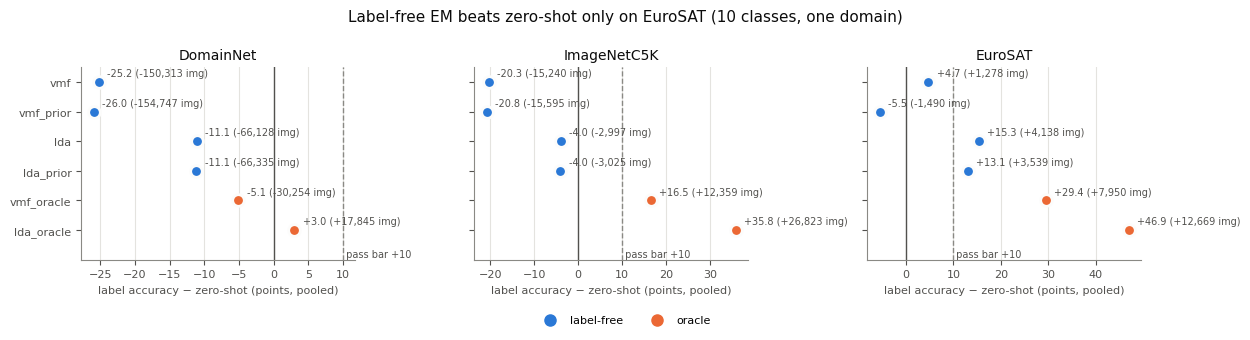

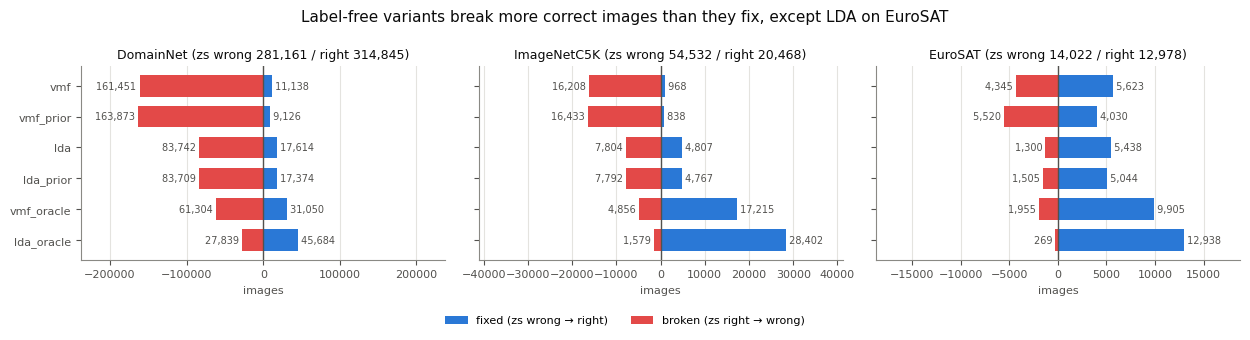

In [5]:
fig = plot_gain(tables, PASS_POINTS); plt.show()
fig = plot_fixed_broken(tables); plt.show()

## 5. Mechanism

Two questions. (a) Does accuracy improve or degrade as EM runs, and does the log-likelihood keep rising while it
does? (b) What do the components track: the true class, or the domain? Normalised mutual information (NMI) of the
predicted component with the class and with the domain, per iteration (multi-domain datasets only).


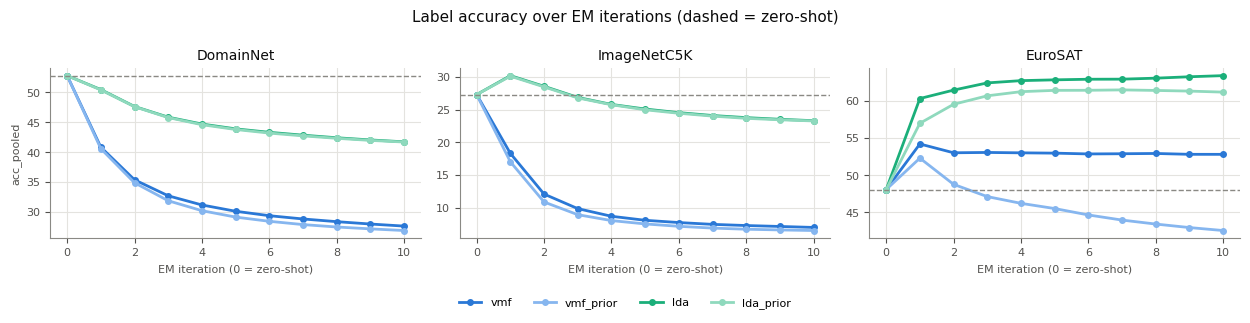

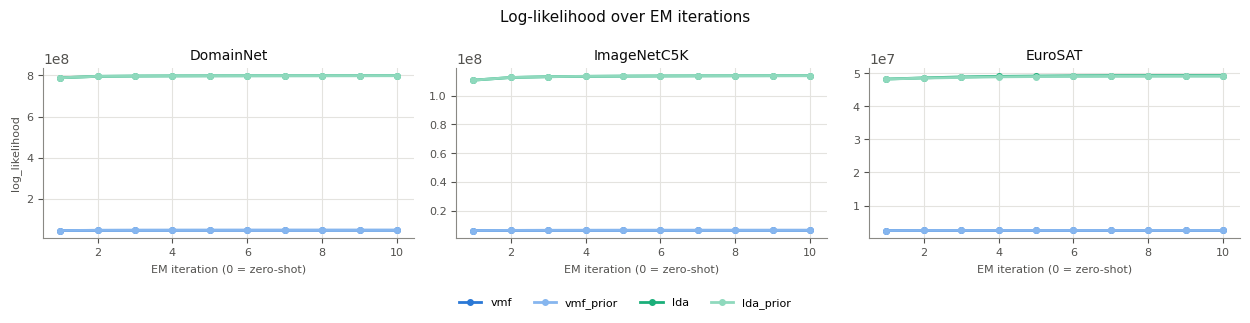

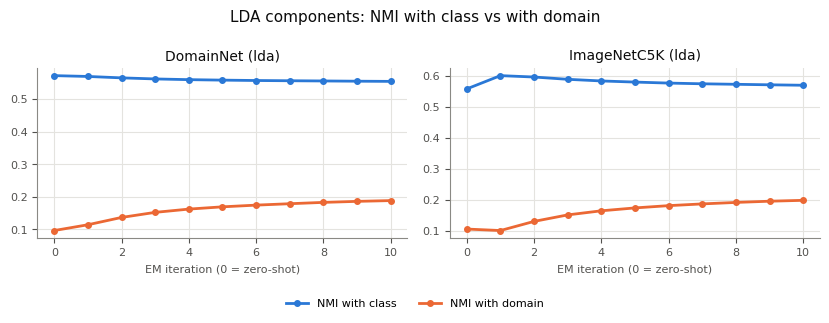

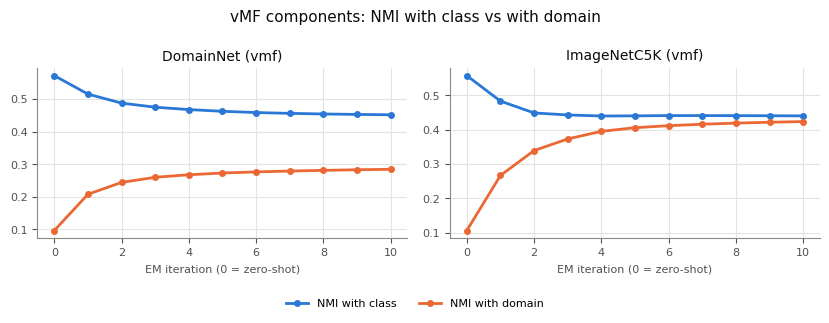

,dataset,variant,acc_iter0,acc_iter1,best_iter,acc_best,acc_iter10,nmi_class_0,nmi_class_10,nmi_domain_0,nmi_domain_10
0,DomainNet,vmf,52.826,40.825,0,52.826,27.606,0.571,0.451,0.096,0.284
1,DomainNet,lda,52.826,50.482,0,52.826,41.731,0.571,0.554,0.096,0.188
2,ImageNetC5K,vmf,27.291,18.295,0,27.291,6.971,0.558,0.440,0.106,0.424
3,ImageNetC5K,lda,27.291,30.188,1,30.188,23.295,0.558,0.570,0.106,0.199
4,EuroSAT,vmf,48.067,54.196,1,54.196,52.800,0.424,0.548,0.000,0.000
5,EuroSAT,lda,48.067,60.311,10,63.393,63.393,0.424,0.697,0.000,0.000


In [6]:
fig = plot_iterations(iters, 'acc_pooled', 'Label accuracy over EM iterations (dashed = zero-shot)'); plt.show()
fig = plot_iterations(iters, 'log_likelihood', 'Log-likelihood over EM iterations'); plt.show()
fig = plot_alignment(iters, 'lda', 'LDA components: NMI with class vs with domain'); plt.show()
fig = plot_alignment(iters, 'vmf', 'vMF components: NMI with class vs with domain'); plt.show()
rows = []
for ds, per in iters.items():
    for v in ('vmf', 'lda'):
        d = per[v].set_index('iteration')
        best = d['acc_pooled'].idxmax()
        rows.append(dict(dataset=ds, variant=v, acc_iter0=d.loc[0, 'acc_pooled'], acc_iter1=d.loc[1, 'acc_pooled'],
                         best_iter=best, acc_best=d.loc[best, 'acc_pooled'], acc_iter10=d.loc[10, 'acc_pooled'],
                         nmi_class_0=d.loc[0, 'nmi_class'], nmi_class_10=d.loc[10, 'nmi_class'],
                         nmi_domain_0=d.loc[0, 'nmi_domain'], nmi_domain_10=d.loc[10, 'nmi_domain']))
display(pd.DataFrame(rows).round(3))


## 6. Interpretation

**Verdict: hypothesis not supported.** No label-free variant passes the pre-registered bar on any dataset.

| Dataset | zero-shot (pooled) | best label-free at iteration 10 | fixed / broken | verdict | LDA oracle (true labels) |
|---|---|---|---|---|---|
| DomainNet | 52.83 | `lda` 41.73 (−11.10) | 17,614 / 83,742 | hurts | 55.82 (+2.99) |
| ImageNet-C | 27.29 | `lda` 23.29 (−4.00) | 4,807 / 7,804 | hurts | 63.05 (+35.76) |
| EuroSAT | 48.07 | `lda` 63.39 (+15.33) | 5,438 / 1,300 (10.0% of zs-right) | weak (break rate > 5%) | 94.99 (+46.92) |

vMF variants are worse everywhere except EuroSAT (+4.73): DomainNet 27.61 (−25.22), ImageNet-C 6.97 (−20.32).
A learned prior never helps (it lowers accuracy or leaves it unchanged in every pair).

**What the numbers say.**
- *EM finds structure, but not classes.* The log-likelihood rises at every iteration on every dataset, while
  accuracy falls on DomainNet and ImageNet-C. The components' NMI with the **domain** rises (DomainNet vMF
  0.10 → 0.28, LDA 0.10 → 0.19; ImageNet-C vMF 0.11 → 0.42, LDA 0.11 → 0.20). Their NMI with the **class**
  falls for vMF (DomainNet 0.57 → 0.45, ImageNet-C 0.56 → 0.44) and for LDA on DomainNet (0.57 → 0.55). The
  densest structure in CLIP image space on these mixed streams is domain or corruption, so maximising likelihood
  pulls the class components towards it. The same domain dominance appeared in 2026-11-03 (quickdraw coherence)
  and 2026-11-06 (cluster shift).
- *LDA on ImageNet-C is a second failure mode.* Class NMI stays flat (0.56 → 0.57) while accuracy falls
  30.19 → 23.29. NMI ignores names, so the components keep class-related groupings but attach them to the wrong
  class names. This is consistent with label switching (shown on synthetic data in `test_gmm.py`), but it was not
  measured directly here.
- *EuroSAT is the exception for the same reason.* It has one domain, so the clusters are the classes (as in the
  cluster-shift run) and EM moves labels the right way: +15.33 points, 5,438 fixed. But 1,300 of 12,978
  zero-shot-right images (10.0%) break. On EuroSAT the kNN target broke 1,381 and cost Ramen 10 points (2026-11-04).
- *The model family limits DomainNet even with labels.* Fitted on the test images with their true labels, one
  Gaussian per class reaches only 55.82% pooled (+2.99), and the vMF oracle is below zero-shot (−5.08).
  Hypothesis (not tested): a DomainNet class spans six styles (real photo to quickdraw), so one mode per class cannot
  represent it, while the text embedding is style-neutral.
- *Iteration 1 of `lda` on ImageNet-C is +2.90 (30.19%)*, then it declines. That is a post-hoc pick, below the bar,
  and it does not hold on DomainNet (iteration 1 is −2.34).

**What this does not show.** The fit is transductive with one $\kappa$ (100) and one shrinkage (0.1); other values
were not tried. Mixtures with several components per class, or fitted after removing a domain or cluster offset,
were not tried. Seed does not matter for this fit (order-free), so a single run per dataset is complete, but it is
one model per dataset.

**Next step.** A class mixture over raw CLIP embeddings is a dead end on multi-domain data. The one variant worth
an oracle check is *domain-factored*: subtract the domain (or k-means cluster) mean first, then fit the class
mixture. Run `lda_oracle` on domain-centred embeddings first. If even that ceiling is not far above +2.99 on
DomainNet, drop the direction. On EuroSAT alone, the `lda` label could be tried as Ramen's CE target. It is +15.3
points at 10% breaks; the oracle mix at that accuracy (61%) gave +17.55 with zero breaks. This is the only
GPU-worthy follow-up, and a small-label-space result.


## 7. Glossary

| Term | Meaning |
|---|---|
| zero-shot | CLIP's prediction $\arg\max_c z^\top w_c$ with no adaptation (cached NoAdapt run) |
| filing | the class queue Ramen writes an image into: its zero-shot prediction |
| EM | expectation-maximisation: alternately fit class models to soft assignments (M) and recompute the assignments (E) |
| vMF | von Mises-Fisher distribution on the unit sphere, $p(z\mid c)\propto e^{\kappa\mu_c^\top z}$; zero-shot is its posterior with $\mu_c = w_c$, $\kappa=100$ |
| LDA | Gaussian classes with one shared covariance (linear discriminant), here fitted without labels by EM |
| shrinkage | blending the covariance with a scaled identity to keep it well conditioned |
| learned prior | class frequencies $\pi_c = N_c/N$ re-estimated by EM (earlier work: drifts onto zero-shot's sink classes) |
| oracle | uses true labels; an upper bound, not a method |
| fixed / broken | zero-shot wrong → new label right / zero-shot right → new label wrong |
| rescue rate / break rate | fixed ÷ zero-shot wrong / broken ÷ zero-shot right |
| pooled / domain-averaged | accuracy over all images / mean of per-domain accuracies |
| NMI | normalised mutual information between two labelings (0 independent, 1 identical up to renaming) |
| noise floor | 2 × (max − min) of Ramen's accuracy over seeds 0–4; here a minimum effect size only |
| transductive | fitted on all test images at once (not causal / streaming) |
| label switching | EM finds a cluster but names it after the wrong class, because the start put that name nearest it |
